In [1]:
# Smart patient monitoring and health alert system

In [2]:
import pandas as pd
import numpy as np

from google.colab import files
uploaded = files.upload()

Saving Patient_Monitoring_KNN.csv to Patient_Monitoring_KNN (3).csv


In [3]:
df = pd.read_csv('Patient_Monitoring_KNN.csv')
df.head()

,Patient Number,Heart Rate (bpm),SpO2 Level (%),Systolic Blood Pressure (mmHg),Diastolic Blood Pressure (mmHg),Body Temperature (°C),Fall Detection,Predicted Disease,Data Accuracy (%),Heart Rate Alert,SpO2 Level Alert,Blood Pressure Alert,Temperature Alert
0,1,98,96,120,86,38.1,No,Diabetes Mellitus,95,NORMAL,NORMAL,NORMAL,ABNORMAL
1,2,105,97,177,104,37.6,No,Heart Disease,91,ABNORMAL,NORMAL,ABNORMAL,ABNORMAL
2,3,90,85,139,57,37.0,No,Asthma,98,NORMAL,ABNORMAL,NORMAL,NORMAL
3,4,102,87,101,77,36.4,No,Asthma,87,ABNORMAL,ABNORMAL,NORMAL,NORMAL
4,5,81,95,172,119,37.7,No,Hypertension,88,NORMAL,NORMAL,ABNORMAL,ABNORMAL


In [4]:

# Check dataset information
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumns:")
print(df.columns.tolist())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check target distribution
print("\nTarget Distribution:")
print(df['SpO2 Level Alert'].value_counts())


Dataset Shape: (60000, 13)

Columns:
['Patient Number', 'Heart Rate (bpm)', 'SpO2 Level (%)', 'Systolic Blood Pressure (mmHg)', 'Diastolic Blood Pressure (mmHg)', 'Body Temperature (°C)', 'Fall Detection', 'Predicted Disease', 'Data Accuracy (%)', 'Heart Rate Alert', 'SpO2 Level Alert', 'Blood Pressure Alert', 'Temperature Alert']

Missing Values:
Patient Number                     0
Heart Rate (bpm)                   0
SpO2 Level (%)                     0
Systolic Blood Pressure (mmHg)     0
Diastolic Blood Pressure (mmHg)    0
Body Temperature (°C)              0
Fall Detection                     0
Predicted Disease                  0
Data Accuracy (%)                  0
Heart Rate Alert                   0
SpO2 Level Alert                   0
Blood Pressure Alert               0
Temperature Alert                  0
dtype: int64

Target Distribution:
SpO2 Level Alert
NORMAL      34770
ABNORMAL    25230
Name: count, dtype: int64


In [5]:

# Step 3: Select Features and Target

features = [
    'Heart Rate (bpm)',
    'SpO2 Level (%)',
    'Systolic Blood Pressure (mmHg)',
    'Diastolic Blood Pressure (mmHg)',
    'Body Temperature (°C)'
]

X = df[features]
y = df['SpO2 Level Alert']

# Display the selected data
print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)


Features:
   Heart Rate (bpm)  SpO2 Level (%)  Systolic Blood Pressure (mmHg)  \
0                98              96                             120   
1               105              97                             177   
2                90              85                             139   
3               102              87                             101   
4                81              95                             172   

   Diastolic Blood Pressure (mmHg)  Body Temperature (°C)  
0                               86                   38.1  
1                              104                   37.6  
2                               57                   37.0  
3                               77                   36.4  
4                              119                   37.7  

Target:
0      NORMAL
1      NORMAL
2    ABNORMAL
3    ABNORMAL
4      NORMAL
Name: SpO2 Level Alert, dtype: object

Features Shape: (60000, 5)
Target Shape: (60000,)


In [6]:

# Step 4: Split the dataset

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (48000, 5)
Testing data: (12000, 5)


In [7]:

# Step 5: Standardize the features

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Training data standardized successfully!")
print("Testing data standardized successfully!")


Training data standardized successfully!
Testing data standardized successfully!


In [8]:

# Step 6: Train the KNN Model

from sklearn.neighbors import KNeighborsClassifier

# Create the KNN model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn_model.fit(X_train_scaled, y_train)

print("KNN Model trained successfully!")


KNN Model trained successfully!


In [9]:

# Step 7: Make Predictions

y_pred = knn_model.predict(X_test_scaled)

print("Predictions completed successfully!")

print("\nFirst 10 Predictions:")
print(y_pred[:10])

print("\nActual Values:")
print(y_test.iloc[:10].values)


Predictions completed successfully!

First 10 Predictions:
['NORMAL' 'ABNORMAL' 'ABNORMAL' 'NORMAL' 'NORMAL' 'NORMAL' 'NORMAL'
 'ABNORMAL' 'ABNORMAL' 'NORMAL']

Actual Values:
['NORMAL' 'ABNORMAL' 'ABNORMAL' 'NORMAL' 'NORMAL' 'NORMAL' 'NORMAL'
 'ABNORMAL' 'ABNORMAL' 'NORMAL']


In [10]:

# Step 8: Evaluate the KNN Model

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Model Accuracy: 99.225 %

Classification Report:
              precision    recall  f1-score   support

    ABNORMAL       0.99      0.99      0.99      5046
      NORMAL       0.99      0.99      0.99      6954

    accuracy                           0.99     12000
   macro avg       0.99      0.99      0.99     12000
weighted avg       0.99      0.99      0.99     12000


Confusion Matrix:
[[4994   52]
 [  41 6913]]


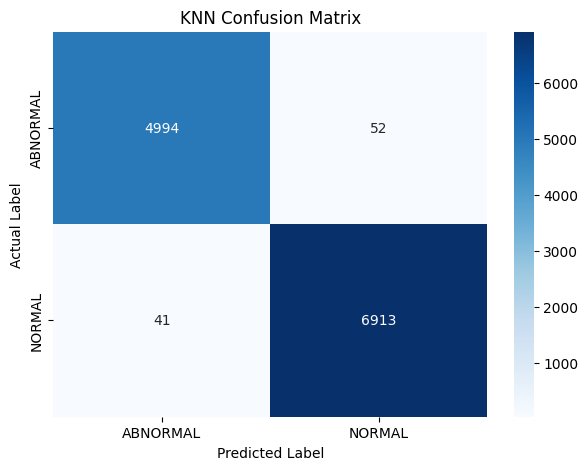

In [11]:

# Step 9 option: Visualize Confusion Matrix

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['ABNORMAL', 'NORMAL'],
    yticklabels=['ABNORMAL', 'NORMAL']
)

plt.title('KNN Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()


In [12]:

# Step 10: Test a New Patient

new_patient = pd.DataFrame([{
    'Heart Rate (bpm)': 100,
    'SpO2 Level (%)': 89,
    'Systolic Blood Pressure (mmHg)': 120,
    'Diastolic Blood Pressure (mmHg)': 80,
    'Body Temperature (°C)': 37
}])

# Apply the same scaler
new_patient_scaled = scaler.transform(new_patient)

# Predict the alert
prediction = knn_model.predict(new_patient_scaled)

print("New Patient Prediction:", prediction[0])


New Patient Prediction: ABNORMAL


In [13]:

# Test a Normal Patient Reading

normal_patient = pd.DataFrame([{
    'Heart Rate (bpm)': 75,
    'SpO2 Level (%)': 98,
    'Systolic Blood Pressure (mmHg)': 120,
    'Diastolic Blood Pressure (mmHg)': 80,
    'Body Temperature (°C)': 37
}])

normal_scaled = scaler.transform(normal_patient)

normal_prediction = knn_model.predict(normal_scaled)

print("Prediction:", normal_prediction[0])


Prediction: NORMAL


In [16]:

# Step 11: Interactive Patient Monitoring Interface

import ipywidgets as widgets
from IPython.display import display, clear_output

heart_rate = widgets.FloatText(value=75, description='Heart Rate:')
spo2 = widgets.FloatText(value=98, description='SpO2:')
systolic = widgets.FloatText(value=120, description='Systolic BP:')
diastolic = widgets.FloatText(value=80, description='Diastolic BP:')
temperature = widgets.FloatText(value=37, description='Temperature:')

button = widgets.Button(
    description='Predict Health Alert',
    button_style='success'
)

output = widgets.Output()

def predict_patient(b):
    with output:
        clear_output()

        # Input validation: SpO2 must be between 0 and 100
        if spo2.value < 0 or spo2.value > 100:
            print("Invalid SpO2 value. It must be between 0 and 100.")
            return

        patient = pd.DataFrame([{
            'Heart Rate (bpm)': heart_rate.value,
            'SpO2 Level (%)': spo2.value,
            'Systolic Blood Pressure (mmHg)': systolic.value,
            'Diastolic Blood Pressure (mmHg)': diastolic.value,
            'Body Temperature (°C)': temperature.value
        }])

        scaled = scaler.transform(patient)
        result = knn_model.predict(scaled)[0]

        print("Patient Monitoring Result")

        if result == "ABNORMAL":
            print("ALERT: ABNORMAL SpO2 LEVEL")
        else:
            print("Status: NORMAL SpO2 LEVEL")

button.on_click(predict_patient)

display(
    widgets.VBox([
        widgets.HTML("<h2>Smart Patient Monitoring System</h2>"),
        heart_rate,
        spo2,
        systolic,
        diastolic,
        temperature,
        button,
        output
    ])
)

In [17]:
# Edge Case Testing

edge_patients = pd.DataFrame([
    {
        'Heart Rate (bpm)': 75,
        'SpO2 Level (%)': 94,
        'Systolic Blood Pressure (mmHg)': 120,
        'Diastolic Blood Pressure (mmHg)': 80,
        'Body Temperature (°C)': 37
    },
    {
        'Heart Rate (bpm)': 75,
        'SpO2 Level (%)': 95,
        'Systolic Blood Pressure (mmHg)': 120,
        'Diastolic Blood Pressure (mmHg)': 80,
        'Body Temperature (°C)': 37
    }
])

scaled_patients = scaler.transform(edge_patients)
predictions = knn_model.predict(scaled_patients)

print("Edge Case Test Results:")
print("SpO2 = 94%:", predictions[0])
print("SpO2 = 95%:", predictions[1])

Edge Case Test Results:
SpO2 = 94%: NORMAL
SpO2 = 95%: NORMAL


In [18]:
extreme_patients = pd.DataFrame([
    {
        'Heart Rate (bpm)': 75,
        'SpO2 Level (%)': 84,
        'Systolic Blood Pressure (mmHg)': 120,
        'Diastolic Blood Pressure (mmHg)': 80,
        'Body Temperature (°C)': 37
    },
    {
        'Heart Rate (bpm)': 75,
        'SpO2 Level (%)': 100,
        'Systolic Blood Pressure (mmHg)': 120,
        'Diastolic Blood Pressure (mmHg)': 80,
        'Body Temperature (°C)': 37
    }
])

scaled_extreme = scaler.transform(extreme_patients)
predictions = knn_model.predict(scaled_extreme)

print("SpO2 = 84%:", predictions[0])
print("SpO2 = 100%:", predictions[1])

SpO2 = 84%: ABNORMAL
SpO2 = 100%: NORMAL


In [19]:
invalid_patients = pd.DataFrame([
    {
        'Heart Rate (bpm)': 75,
        'SpO2 Level (%)': 50,
        'Systolic Blood Pressure (mmHg)': 120,
        'Diastolic Blood Pressure (mmHg)': 80,
        'Body Temperature (°C)': 37
    },
    {
        'Heart Rate (bpm)': 75,
        'SpO2 Level (%)': 110,
        'Systolic Blood Pressure (mmHg)': 120,
        'Diastolic Blood Pressure (mmHg)': 80,
        'Body Temperature (°C)': 37
    }
])

scaled_invalid = scaler.transform(invalid_patients)
predictions = knn_model.predict(scaled_invalid)

print("SpO2 = 50%:", predictions[0])
print("SpO2 = 110%:", predictions[1])

SpO2 = 50%: ABNORMAL
SpO2 = 110%: NORMAL


In [20]:
# Comparison: does KNN really need all 5 features?
def knn_accuracy(cols):
    Xtr, Xte, ytr, yte = train_test_split(
        df[cols], y, test_size=0.20, random_state=42, stratify=y)
    sc = StandardScaler()
    m = KNeighborsClassifier(n_neighbors=5)
    m.fit(sc.fit_transform(Xtr), ytr)
    return m.score(sc.transform(Xte), yte) * 100

print("Baseline (always guess majority class):", round(y.value_counts(normalize=True).max() * 100, 2), "%")
print("KNN with all 5 features:", round(knn_accuracy(features), 2), "%")
print("KNN with SpO2 only:", round(knn_accuracy(['SpO2 Level (%)']), 2), "%")
print("KNN without SpO2:", round(knn_accuracy([f for f in features if 'SpO2' not in f]), 2), "%")

Baseline (always guess majority class): 57.95 %
KNN with all 5 features: 99.22 %
KNN with SpO2 only: 100.0 %
KNN without SpO2: 69.53 %
